In [37]:
import ast
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Налаштування середовища
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')

In [38]:
# ==============================================================================
# 1. ЗАВАНТАЖЕННЯ ТА ПІДГОТОВКА ДАНИХ
# ==============================================================================
def extract_cpu(val):
    if pd.isna(val): return np.nan
    if isinstance(val, (int, float)): return float(val)
    if isinstance(val, str):
        val_clean = val.strip()
        try:
            parsed = ast.literal_eval(val_clean)
            if isinstance(parsed, dict):
                return parsed.get('cpus', parsed.get('cpu', np.nan))
        except: pass
        try: return float(val_clean)
        except: pass
    return np.nan

df_raw = pd.read_csv('borg_traces_data.csv', nrows=50000)
target_col = next((col for col in ['average_usage', 'resource_request', 'maximum_usage'] if col in df_raw.columns), None)

cpu_series = df_raw[target_col].apply(extract_cpu)
cpu_series = cpu_series.fillna(cpu_series.median() if pd.notnull(cpu_series.median()) else 0.2)
cpu_load = cpu_series.values

max_val = np.nanmax(cpu_load)
cpu_load = (cpu_load * 100) if max_val <= 1.0 else (cpu_load / max_val * 100)

In [39]:
# ==============================================================================
# 2. ФОРМУВАННЯ ОЗНАК (FEATURE ENGINEERING)
# ==============================================================================
hours = np.arange(len(cpu_load)) / 12
# Імітація погодних умов
outdoor_temp = 15 + 8 * np.sin(hours / 24 * 2 * np.pi) + 5 * np.sin(hours / (24*30) * 2 * np.pi) + np.random.normal(0, 1.5, len(hours))
# Формування цільової змінної
cooling_energy = 20 + 0.8 * cpu_load + 1.2 * outdoor_temp + np.random.normal(0, 4, len(hours))

df = pd.DataFrame({
    'Hour_of_Day': (hours % 24).astype(int),
    'CPU_Load_Percent': cpu_load,
    'Outdoor_Temp_C': outdoor_temp,
    'Cooling_Energy_kW': cooling_energy
})

# Додавання лагових ознак та взаємодій для Time Series
df['CPU_Lag1'] = df['CPU_Load_Percent'].shift(1).bfill()
df['CPU_Lag3'] = df['CPU_Load_Percent'].shift(3).bfill()
df['CPU_Rolling_Mean'] = df['CPU_Load_Percent'].rolling(window=6, min_periods=1).mean()
df['Temp_CPU_Interaction'] = df['Outdoor_Temp_C'] * df['CPU_Load_Percent']

In [43]:
# ==============================================================================
# 3. НАВЧАННЯ ML-МОДЕЛІ
# ==============================================================================
features = ['Hour_of_Day', 'Outdoor_Temp_C', 'CPU_Load_Percent', 'CPU_Lag1', 'CPU_Lag3', 'CPU_Rolling_Mean', 'Temp_CPU_Interaction']
X = df[features]
y = df['Cooling_Energy_kW']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, shuffle=False)

model = HistGradientBoostingRegressor(
    max_iter=600,
    learning_rate=0.02,
    max_leaf_nodes=63,
    min_samples_leaf=15,
    l2_regularization=0.5,
    random_state=42
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

       МЕТРИКИ ОЦІНЮВАННЯ ЯКОСТІ МОДЕЛІ      
MAE  (Середня абсолютна похибка):    3.25 кВт
RMSE (Корінь із середньоквадрат.):   4.08 кВт
MAPE (Середня відносна похибка):    9.00 %
R²   (Коефіцієнт детермінації):      0.8082


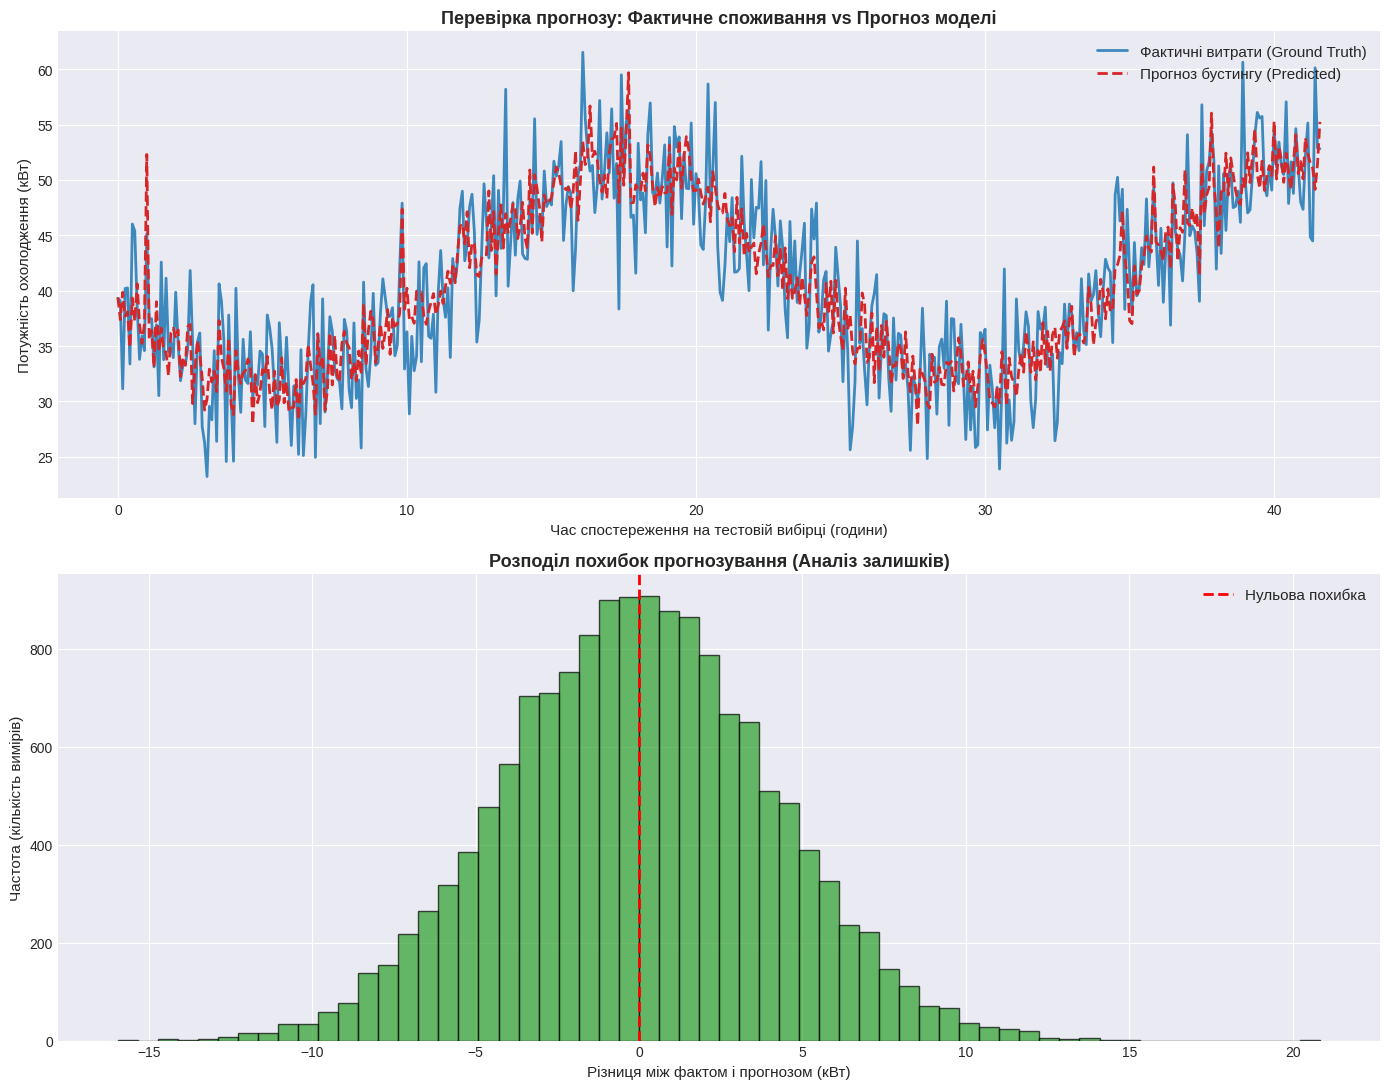

In [41]:
# ==============================================================================
# 4. ОЦІНКА ЯКОСТІ ТА ВІЗУАЛІЗАЦІЯ
# ==============================================================================
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print("=" * 45)
print("       МЕТРИКИ ОЦІНЮВАННЯ ЯКОСТІ МОДЕЛІ      ")
print("=" * 45)
print(f"MAE  (Середня абсолютна похибка):    {mae:.2f} кВт")
print(f"RMSE (Корінь із середньоквадрат.):   {rmse:.2f} кВт")
print(f"MAPE (Середня відносна похибка):    {mape:.2f} %")
print(f"R²   (Коефіцієнт детермінації):      {r2:.4f}")
print("=" * 45)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 11))

# Графік прогнозу
window = 500
time_axis = np.arange(window) * 5 / 60

ax1.plot(time_axis, y_test.values[:window], label='Фактичні витрати (Ground Truth)', color='#1f77b4', alpha=0.85, linewidth=2)
ax1.plot(time_axis, y_pred[:window], label='Прогноз бустингу (Predicted)', color='#d62728', linestyle='--', linewidth=2)
ax1.set_title('Перевірка прогнозу: Фактичне споживання vs Прогноз моделі', fontsize=13, fontweight='bold')
ax1.set_xlabel('Час спостереження на тестовій вибірці (години)', fontsize=11)
ax1.set_ylabel('Потужність охолодження (кВт)', fontsize=11)
ax1.legend(loc='upper right', fontsize=11)

# Графік залишків
residuals = y_test - y_pred
ax2.hist(residuals, bins=60, color='#2ca02c', edgecolor='black', alpha=0.7)
ax2.axvline(0, color='red', linestyle='--', linewidth=2, label='Нульова похибка')
ax2.set_title('Розподіл похибок прогнозування (Аналіз залишків)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Різниця між фактом і прогнозом (кВт)', fontsize=11)
ax2.set_ylabel('Частота (кількість вимірів)', fontsize=11)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()